# OrdinalCLIP Supervised Simulation - DeepDRiD

This notebook runs a full supervised simulation (all 1200 training images) using the **OrdinalCLIP** backbone (plain rank prompt learner, no cross-modal pairwise loss).

Checkpoints will be saved automatically, ensuring the run is fully resumable.

In [1]:
import os, sys, warnings
from pathlib import Path
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint
import omegaconf
import re

warnings.filterwarnings('ignore')

ROOT = Path.cwd()
while not (ROOT / 'configs').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from scripts.train import load_config
from src.models.runner import FewShotOrdinalRunner

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Project root : {ROOT}')
print(f'Device       : {DEVICE}')

Project root : d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace
Device       : cuda


## 1. Load Data (Supervised Splits)

In [2]:

_MEAN = (0.485, 0.456, 0.406)
_STD  = (0.229, 0.224, 0.225)

def get_transform(is_train: bool = True):
    if is_train:
        return transforms.Compose([
            transforms.Resize(256),
            transforms.RandomCrop(224),
            transforms.RandomHorizontalFlip(),
            transforms.RandomVerticalFlip(),
            transforms.ColorJitter(0.3, 0.3, 0.3, 0.1),
            transforms.ToTensor(),
            transforms.Normalize(_MEAN, _STD),
        ])
    return transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(_MEAN, _STD),
    ])

class DeepDRDataset(Dataset):
    """Handles the nested  Images/<patient_id>/<image_id>.jpg  path structure."""
    def __init__(self, df, images_root, transform):
        self.df        = df.reset_index(drop=True)
        self.root      = Path(images_root)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        fn  = str(row["Filename"])
        pid = re.match(r"^(\d+)_?", fn).group(1)
        img = Image.open(self.root / pid / fn).convert("RGB")
        # Our models expect (image, target, path, index) but the unpack expects 4 items
        return self.transform(img), int(row["Label"]), str(self.root / pid / fn), idx

TRAIN_CSV = ROOT / "repos/OrdinalDRSimulation/OrdinalDRGrading/data/splits/DeepDRiD/train.csv"
VAL_CSV   = ROOT / "repos/OrdinalDRSimulation/OrdinalDRGrading/data/splits/DeepDRiD/val.csv"
DEEPDR_ROOT   = Path("G:/Datasets/DR/DeepDR/DeepDRiD-master/regular_fundus_images")
TRAIN_IMG_DIR = DEEPDR_ROOT / "regular-fundus-training" / "Images"
VAL_IMG_DIR   = DEEPDR_ROOT / "regular-fundus-validation" / "Images"

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)

train_dataset = DeepDRDataset(train_df, TRAIN_IMG_DIR, get_transform(True))
val_dataset = DeepDRDataset(val_df, VAL_IMG_DIR, get_transform(False))

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)
print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")

Train batches: 19, Val batches: 7


## 2. Model & Trainer Configuration

In [3]:

cfg = load_config("configs/deepdrid_cfp.yaml", ["train.epochs=50", "train.lr=1e-4"])
# Ensure we are using OrdinalCLIP and no pairwise loss
cfg.model.prompt_learner.name = "ordinalclip_rank_prompt_learner"
cfg.loss.mu_pairwise = 0.0

out_dir = ROOT / "results" / "OrdinalCLIP_Supervised" / "DeepDRiD"
out_dir.mkdir(parents=True, exist_ok=True)

callbacks = [
    ModelCheckpoint(dirpath=str(out_dir), filename='best', monitor='val_qwk', mode='max', save_top_k=1, save_last=True),
]

try:
    prec = 'bf16-mixed' if torch.cuda.is_bf16_supported() else '32-true'
except:
    prec = '32-true'

trainer = pl.Trainer(
    max_epochs=50,
    accelerator='auto', devices=1,
    precision=prec,
    gradient_clip_val=1.0,
    callbacks=callbacks,
    log_every_n_steps=5,
    enable_checkpointing=True,
    enable_progress_bar=True,
)


Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


## 3. Training Loop (Resumable)

In [5]:

ckpt_path = out_dir / "last.ckpt"
if ckpt_path.exists():
    print(f"Resuming from {ckpt_path}")
    # Register DictConfig as a safe global to fix PyTorch 2.6 UnpicklingError
    try:
        torch.serialization.add_safe_globals([omegaconf.dictconfig.DictConfig])
    except:
        pass
    model = FewShotOrdinalRunner.load_from_checkpoint(ckpt_path, cfg=cfg, weights_only=False)
    trainer.fit(model, train_dataloaders=train_loader, val_dataloaders=val_loader, ckpt_path=str(ckpt_path))
else:
    print("Starting training from scratch")
    model = FewShotOrdinalRunner(cfg)
    trainer.fit(model, train_dataloaders=train_loader, val_dataloaders=val_loader)


Starting training from scratch


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Trainable parameters: 26494897


┏━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name               ┃ Type                   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ clip_model         │ CLIP                   │  103 M │ eval  │     0 │
│ 1 │ text_encoder       │ TextEncoder            │ 38.4 M │ train │     0 │
│ 2 │ prompt_learner     │ OrdinalCLIPHead        │  9.7 K │ train │     0 │
│ 3 │ sms                │ SMS                    │      0 │ train │     0 │
│ 4 │ criterion_main     │ CrossEntropyLoss       │      0 │ train │     0 │
│ 5 │ criterion_rank     │ RankingAwareLoss       │      0 │ train │     0 │
│ 6 │ criterion_pairwise │ CrossModalPairwiseLoss │      0 │ train │     0 │
└───┴────────────────────┴────────────────────────┴────────┴───────┴───────┘

Trainable params: 26.5 M                                                                                           
Non-trainable params: 76.7 M                                                                                       
Total params: 103 M                                                                                                
Total estimated model params size (MB): 412.821                                                                    
Modules in train mode: 518                                                                                         
Modules in eval mode: 325                                                                                          
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=50` reached.


In [8]:
print("Done! Latest metrics:", model.latest_metrics)

Done! Latest metrics: {'qwk': 0.8243992606284658, 'mae': 0.4175, 'f1': 0.555824049802155, 'auc': 0.8752931547619047, 'acc': 0.66, 'los': 1.0}


## 4. Evaluation and Visualization
Run this section after training has completed to evaluate the model on the validation set.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import torch.nn.functional as F
from tqdm import tqdm

model.eval()
model.cuda()

all_preds = []
all_targets = []
all_probs = []

print("Running inference on validation set...")
with torch.no_grad():
    for batch in tqdm(val_loader):
        images, targets, _, _ = batch
        images = images.cuda()
        
        img_features, txt_features = model(images)
        logit_scale = model.clip_model.logit_scale.exp()
        sim = logit_scale * img_features @ txt_features.T
        
        if model.sms is not None:
            sim = model.sms(sim)
            
        probs = F.softmax(sim, dim=-1)
        preds = probs.argmax(dim=-1)
        
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
all_probs = np.array(all_probs)


Running inference on validation set...


100%|██████████| 7/7 [00:18<00:00,  2.58s/it]


In [10]:
from sklearn.metrics import cohen_kappa_score, roc_auc_score, f1_score, accuracy_score

qwk = cohen_kappa_score(all_targets, all_preds, weights='quadratic')
acc = accuracy_score(all_targets, all_preds)
macro_f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)

try:
    auc = roc_auc_score(all_targets, all_probs, multi_class='ovr', average='macro')
except Exception as e:
    auc = float('nan')
    print("Could not compute AUC:", e)

print("="*40)
print(f"Validation QWK      : {qwk:.4f}")
print(f"Validation ACC      : {acc:.4f}")
print(f"Validation Macro-F1 : {macro_f1:.4f}")
print(f"Validation AUC      : {auc:.4f}")
print("="*40)

print("\nClassification Report:")
print(classification_report(all_targets, all_preds, zero_division=0))


Validation QWK      : 0.8311
Validation ACC      : 0.6575
Validation Macro-F1 : 0.5529
Validation AUC      : 0.8757

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.96      0.89       120
           1       0.61      0.49      0.54        80
           2       0.57      0.54      0.55        80
           3       0.58      0.79      0.67        80
           4       0.23      0.07      0.11        40

    accuracy                           0.66       400
   macro avg       0.56      0.57      0.55       400
weighted avg       0.62      0.66      0.63       400



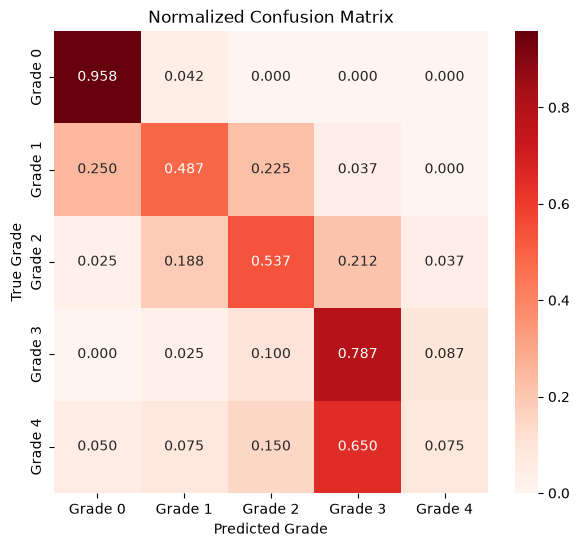

In [17]:
# Normalized Confusion Matrix
cm = confusion_matrix(all_targets, all_preds, normalize='true')

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, cmap='Reds', fmt='.3f', 
            xticklabels=[f"Grade {i}" for i in range(5)], 
            yticklabels=[f"Grade {i}" for i in range(5)])
plt.title("Normalized Confusion Matrix")
plt.xlabel("Predicted Grade")
plt.ylabel("True Grade")
plt.show()


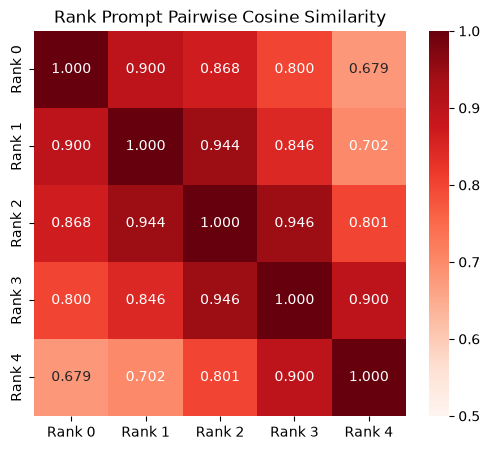

In [16]:
# Similarity Matrix (Rank vs Rank Text Features)
model.eval()
with torch.no_grad():
    prompts, tokenized = model.prompt_learner()
    text_features = model.text_encoder(prompts, tokenized)
    text_features = F.normalize(text_features, dim=-1)
    
    sim_matrix = (text_features @ text_features.T).cpu().numpy()

plt.figure(figsize=(6, 5))
sns.heatmap(sim_matrix, annot=True, cmap='Reds', fmt='.3f', vmin=0.5, vmax=1.0,
            xticklabels=[f"Rank {i}" for i in range(5)], 
            yticklabels=[f"Rank {i}" for i in range(5)])
plt.title("Rank Prompt Pairwise Cosine Similarity")
plt.show()


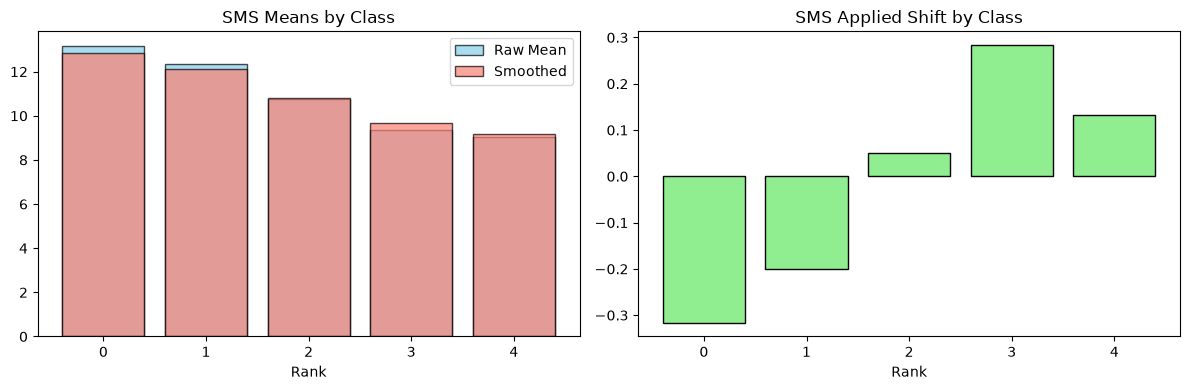

In [15]:
# SMS Plot (if enabled)
if model.sms is not None:
    mu_raw = model.sms.mu_raw.detach().cpu().numpy()
    mu_smooth = model.sms.mu_smooth.detach().cpu().numpy()
    shift = mu_smooth - mu_raw
    
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    
    ax[0].bar(range(5), mu_raw, color='skyblue', edgecolor='black', alpha=0.7, label='Raw Mean')
    ax[0].bar(range(5), mu_smooth, color='salmon', edgecolor='black', alpha=0.7, label='Smoothed')
    ax[0].set_title("SMS Means by Class")
    ax[0].set_xticks(range(5))
    ax[0].set_xlabel("Rank")
    ax[0].legend()
    
    ax[1].bar(range(5), shift, color='lightgreen', edgecolor='black')
    ax[1].set_title("SMS Applied Shift by Class")
    ax[1].set_xticks(range(5))
    ax[1].set_xlabel("Rank")
    
    plt.tight_layout()
    plt.show()
else:
    print("SMS is not enabled in this model configuration.")


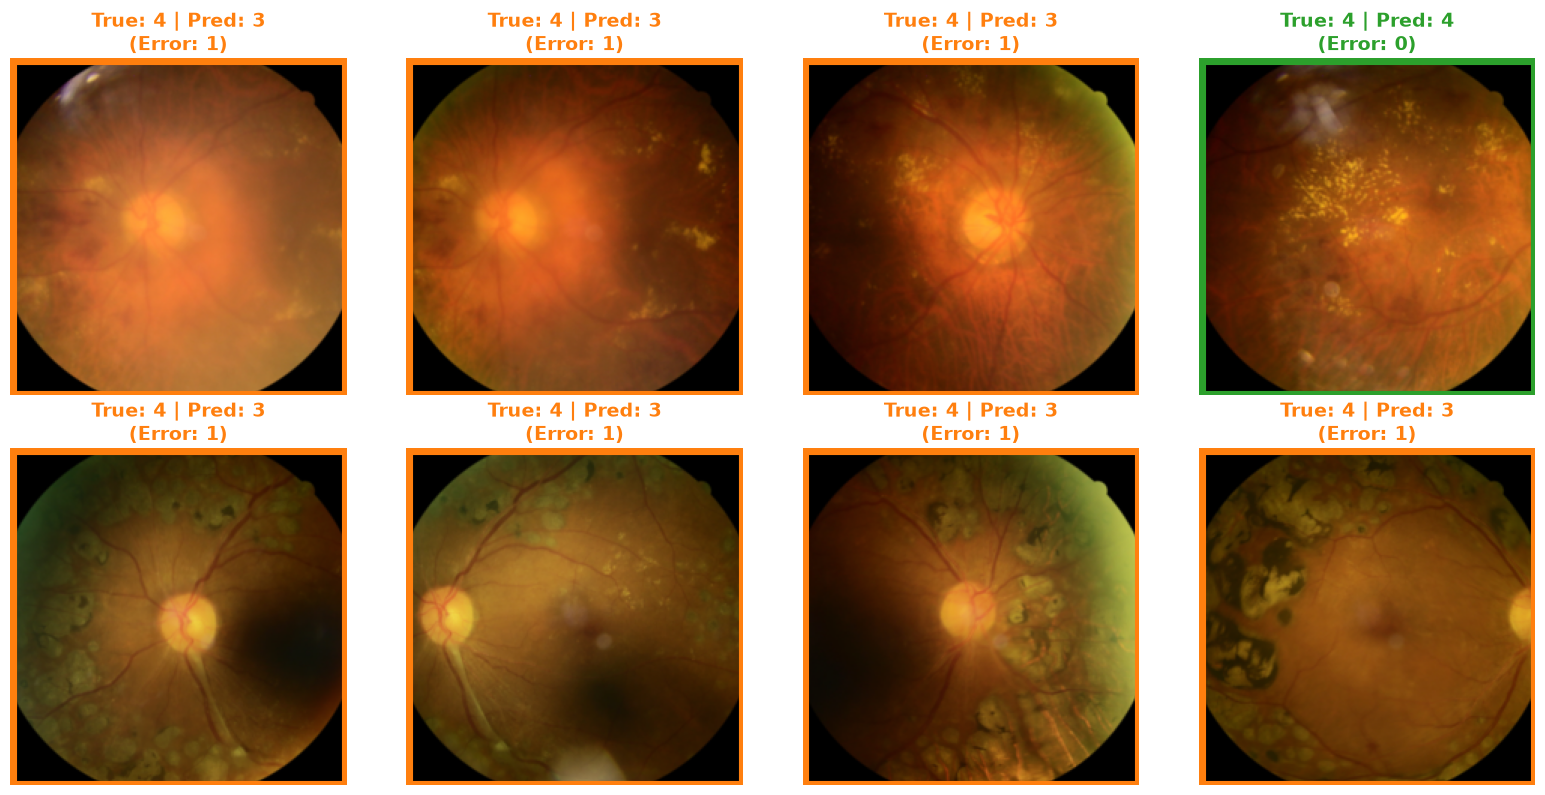

Plots generated successfully!


In [ ]:
import matplotlib.patches as patches
import torchvision.transforms as T

# Qualitative Plot with Ordinal Coloring
model.eval()
model.cpu()

# Get a single batch of images
batch = next(iter(val_loader))
images, targets, paths, _ = batch

# Pick first 8 images
n_imgs = min(8, len(images))
images = images[:n_imgs]
targets = targets[:n_imgs]

with torch.no_grad():
    img_features, txt_features = model(images)
    sim = model.clip_model.logit_scale.exp() * img_features @ txt_features.T
    if model.sms is not None:
        sim = model.sms(sim)
    preds = sim.argmax(dim=-1).numpy()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

# Un-normalize for plotting
inv_normalize = T.Normalize(
    mean=[-m/s for m, s in zip(_MEAN, _STD)],
    std=[1/s for s in _STD]
)

for i in range(n_imgs):
    img = inv_normalize(images[i]).permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)
    
    axes[i].imshow(img)
    axes[i].axis('off')
    
    true_cls = targets[i].item()
    pred_cls = preds[i]
    
    # Border color based on prediction error magnitude (Ordinal Severity)
    # Exact match: Green, off by 1: Orange, off by >=2: Red
    diff = abs(true_cls - pred_cls)
    if diff == 0: border_color = '#2ca02c' # Green
    elif diff == 1: border_color = '#ff7f0e' # Orange
    else: border_color = '#d62728' # Red
    
    # Add a border rectangle
    rect = patches.Rectangle((0, 0), 224, 224, linewidth=8, edgecolor=border_color, facecolor='none')
    axes[i].add_patch(rect)
    
    axes[i].set_title(f"True: {true_cls} | Pred: {pred_cls}\n(Error: {diff})", 
                      color=border_color, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Restore model to device
model.cuda()